# Clustering de documents

## Imports

In [2]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [29]:
from nltk.tokenize import wordpunct_tokenize

def preprocessing(text, stem=True):
    """Tokenize text and keep only alphabetic tokens"""
    return [t for t in wordpunct_tokenize(text) if t.isalpha()]

In [30]:
data_path = "../../data/txt/"

## Choisir une décennie

In [31]:
DECADE = '1940'
data_path = "../../data/txt/"
files = sorted(f for f in os.listdir(data_path)
               if f.endswith(".txt") and f.startswith(f"KB_JB838_{DECADE[:3]}"))
len(files)

1000

## Charger tous les  fichiers de la décennie et en créer une liste de textes

In [32]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [33]:
# Exemple de fichiers
files[:5]

['KB_JB838_1940-01-04_01-00001.txt',
 'KB_JB838_1940-01-05_01-00009.txt',
 'KB_JB838_1940-01-07_01-00014.txt',
 'KB_JB838_1940-01-10_01-00003.txt',
 'KB_JB838_1940-01-11_01-00004.txt']

In [34]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

In [35]:
# Exemple de textes
texts[0][:400]

"54 e ANNEE. — N° 4. Pages - 40 C 1 *® 8 Grand-Duché : 45 centimes. - France : 75 centime». ABONNEMENTS pour la province on Province } s'abonne à là Poste CH' Vüle au $ pour | T , oi , ŒOl# 28>50 BUREAUX ET FILS SPÉCIAUX: — — ■ ; S Un an 170.00 Congo • j Six mol , 85X0 Etranger : Prix euivant conventions VENTE ET ABONNEM. : PLACE DE LOUVAIN. 23 □ SALLE DE DÉPÊCHES : 124. RUE ROYALE BRUXELLES G “ ■“"

## Vectoriser les documents à l'aide de TF-IDF

In [37]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

### Instancier le modèle TF-IDF avec ses arguments

In [40]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,token_pattern=None,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

In [43]:
from nltk.tokenize import wordpunct_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer

def preprocessing(text, stem=True):
    """Tokenize text and keep only alphabetic tokens"""
    return [t for t in wordpunct_tokenize(text) if t.isalpha()]

vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    token_pattern=None,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

# Test : doit afficher une liste de mots, sans erreur
print(vectorizer.tokenizer("Le roi est là, aujourd'hui."))

['Le', 'roi', 'est', 'là', 'aujourd', 'hui']


In [44]:
tfidf_vectors = vectorizer.fit_transform(texts)
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 892888 stored elements and shape (1000, 4379)>

### Construire la matrice de vecteurs à l'aide de la fonction `fit_transform`

In [45]:
tfidf_vectors = vectorizer.fit_transform(texts)

In [46]:
# Détail de la matrice
tfidf_vectors

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 892888 stored elements and shape (1000, 4379)>

### Imprimer le vecteur tf-IDF du premier document

In [47]:
pd.Series(
    tfidf_vectors[0].toarray()[0],
    index=vectorizer.get_feature_names_out()
    ).sort_values(ascending=False)

gouvernement    0.156102
milieux         0.152765
cabinet         0.131239
italie          0.124132
quelle          0.119543
                  ...   
û               0.000000
ü               0.000000
boul            0.000000
œil             0.000000
abri            0.000000
Length: 4379, dtype: float64

## Comprendre les vecteurs et leurs "distances"

In [48]:
cosine([1, 2, 3], [1, 2, 3])

np.float64(0.0)

In [49]:
cosine([1, 2, 3], [1, 2, 2])

np.float64(0.02004211298777725)

In [50]:
cosine([1, 2, 3], [2, 2, 2])

np.float64(0.07417990022744858)

### Tests sur nos documents

In [51]:
tfidf_array = tfidf_vectors.toarray()

In [52]:
# Vecteur du document 0
tfidf_array[0]

array([0.        , 0.        , 0.        , ..., 0.02450869, 0.        ,
       0.06021364], shape=(4379,))

In [53]:
# Vecteur du document 1
tfidf_array[1]

array([0.        , 0.        , 0.        , ..., 0.00584447, 0.00605402,
       0.        ], shape=(4379,))

In [54]:
cosine(tfidf_array[0], tfidf_array[1])

np.float64(0.9565060039661765)

In [55]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(tfidf_vectors)
    print(k, round(silhouette_score(tfidf_vectors, lab), 3), round(km.inertia_))

2 0.121 736
3 0.114 704
4 0.098 684
5 0.109 666
6 0.095 654
7 0.1 638
8 0.102 628
9 0.085 617
10 0.083 610


In [57]:
terms = vectorizer.get_feature_names_out()

for k in (2, 3, 5):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(tfidf_vectors)
    order = km.cluster_centers_.argsort()[:, ::-1]
    print(f"\n===== k = {k} =====")
    for i in range(k):
        print(f"Cluster {i} ({(lab == i).sum()} fichiers) :",
              ", ".join(terms[j] for j in order[i, :12]))


===== k = 2 =====
Cluster 0 (726 fichiers) : gouvernement, ministre, politique, etats, troupes, cap, allemands, janvier, juin, juillet, unis, avril
Cluster 1 (274 fichiers) : ag, rossel, dem, ec, ecr, ecrire, vend, vendre, mod, louer, app, cherche

===== k = 3 =====
Cluster 0 (255 fichiers) : ag, rossel, dem, ec, ecr, ecrire, vend, vendre, mod, louer, app, cherche
Cluster 1 (398 fichiers) : gouvernement, ministre, politique, troupes, etats, allemands, unis, britannique, forces, berlin, front, allemande
Cluster 2 (347 fichiers) : cap, match, course, notaire, équipe, bat, admis, division, mod, ca, juillet, mutuel

===== k = 5 =====
Cluster 0 (54 fichiers) : ag, vend, hp, rossel, ford, cv, vendre, chevrolet, z, ec, pneus, cyl
Cluster 1 (220 fichiers) : ag, rossel, dem, ec, ecr, ecrire, louer, app, mod, vendre, cherche, conf
Cluster 2 (433 fichiers) : gouvernement, ministre, politique, etats, troupes, allemands, unis, britannique, forces, berlin, allemande, front
Cluster 3 (39 fichiers) :

## Appliquer un algorithme de clustering sur les vecteurs TF-IDF des documents

Pour en savoir plus sur le KMeans clustering :
- https://medium.com/dataseries/k-means-clustering-explained-visually-in-5-minutes-b900cc69d175

### Définir un nombre de clusters

In [77]:
import numpy as np, random

N_CLUSTERS = 5
km_model = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=42)
clusters = km_model.fit_predict(tfidf_vectors)
print("Tailles :", np.bincount(clusters))   # attendu : [ 54 220 433  39 254]

def page(f):
    return int(f.split("-")[-1].split(".")[0])

random.seed(1)
for i in range(N_CLUSTERS):
    membres = np.where(clusters == i)[0]
    print(f"\n===== Cluster {i} ({len(membres)} fichiers) =====")
    for j in random.sample(list(membres), 4):
        m = len(texts[j]) // 2
        print(f"- {files[j]} (page {page(files[j])}) :", texts[j][m:m+200].replace("\n", " "))

Tailles : [ 54 220 433  39 254]

===== Cluster 0 (54 fichiers) =====
- KB_JB838_1941-04-26_01-00013.txt (page 13) :  gentl!. pharmacienne. - ■ Ec.As Rw:tl 1:® 47858V TIMBRES-POSTE Amateur ach. comptant timbres beige*, français, tuxemb., hoüacdais. Ec. Ag. Rossel n® 47907 V PARTÏt\ vend 2~piî?« Chine et Japon, bx ta
- KB_JB838_1948-06-05_01-00014.txt (page 14) :  Roue lib. Rad., etc. 5 r. Longtiu 134162 Matford 47 C 1. 12 HP. 4 port, abs, c. nf, tr. p. roui. Crédit si bes., 95. av. de la Couronne. 95. A 1XELLES 14072 2 B. ,11. IV. 3 carhtirat. Packard décapot
- KB_JB838_1949-11-25_01-00013.txt (page 13) : ment deux mois après livraison : JUVA, luxe 1948 24x1840 fr. SIMCA, 1948 24x1840 fr. MECEDES luxe 24x2460 fr. HANSA 24x1320 fr. DYNA COMMERCIALE 1949 24x2610 fr. FORD 1947 24x2661 fr. CITROEN 1948 24x
- KB_JB838_1949-07-09_01-00014.txt (page 14) : - BOURSE rue Ant. Danseect, 2 Brux.-Bourse. 2l712z FIAT 500 - 1941 C. int., exc. état 6.000 + 1.330 p. m. . S1MCA 5, 1947 aecap., parfait ét

In [78]:
import random
random.seed(1)
for i in (2, 0):
    membres = np.where(clusters == i)[0]
    for j in random.sample(list(membres), 4):
        m = len(texts[j]) // 2
        print(f"\n[Cluster {i}] {files[j]}\n", texts[j][m:m+300].replace("\n", " "))


[Cluster 2] KB_JB838_1941-05-26_01-00002.txt
 ’est pas, courant. Suivaient les « Danses villageoises » de Grétry, extraites do différents opéras dù compositeur. Bien' que l'harmonisation et l’orchestration y soient rudimentaires, toutes ces œuvres sont ingénieuses ot Jolies du point de vue mélodique. Elles furent interprétées avec beaucoup de s

[Cluster 2] KB_JB838_1946-07-16_01-00002.txt
 e gauche a constituer un gouvernement stable et cohérent. Il constate que pareille coalition ne peut apporter aucune solution aux grandes questions d'intérêt national qui conditionnent l'avenir du pays et le rétablissement de sa prospérité. » Il souligna « qu'aucune solution durable et apaisante ne 

[Cluster 2] KB_JB838_1949-05-24_01-00003.txt
 ent de rentrer d’Allemagne, explique comme suit le problème économique qui est à la base de la grève des cheminots berlinois. Les Russes ont refusé de payer en mark occidentaux leurs cheminots habitant dans le secteur occidental, ce qui leur fait une économ

### Instancier le modèle K-Means et ses arguments

In [79]:
km_model = KMeans(n_clusters=N_CLUSTERS)

### Appliquer le clustering à l'aide de la fonction `fit_predict`

In [80]:
clusters = km_model.fit_predict(tfidf_vectors)

In [81]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [82]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1940-01-19_01-00005.txt',
               'KB_JB838_1940-02-06_01-00005.txt',
               'KB_JB838_1940-02-07_01-00005.txt',
               'KB_JB838_1940-02-09_01-00005.txt',
               'KB_JB838_1940-02-12_01-00005.txt',
               'KB_JB838_1940-03-04_01-00005.txt',
               'KB_JB838_1940-04-22_01-00005.txt',
               'KB_JB838_1940-06-30_01-00005.txt',
               'KB_JB838_1940-08-02_01-00004.txt',
               'KB_JB838_1940-10-08_01-00005.txt',
               'KB_JB838_1940-10-29_01-00006.txt',
               'KB_JB838_1940-11-05_01-00005.txt',
               'KB_JB838_1940-11-07_01-00005.txt',
               'KB_JB838_1940-12-09_01-00004.txt',
               'KB_JB838_1940-12-11_01-00008.txt',
               'KB_JB838_1941-01-28_01-00005.txt',
               'KB_JB838_1941-03-15_01-00005.txt',
               'KB_JB838_1941-03-17_01-00006.txt',
               'KB_JB838_1941-04-04_01-00008.txt',
               'KB_JB838_1941-0

## Visualiser les clusters

### Réduire les vecteurs à 2 dimensions à l'aide de l'algorithme PCA
Cette étape est nécessaire afin de visualiser les documents dans un espace 2D

https://fr.wikipedia.org/wiki/Analyse_en_composantes_principales

In [83]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [84]:
reduced_vectors[:10]

array([[-0.26660744,  0.16233793],
       [ 0.6204869 ,  0.13541393],
       [ 0.13074405, -0.05731048],
       [-0.30092978,  0.29108964],
       [-0.27798839,  0.14352522],
       [-0.212842  , -0.17838224],
       [-0.29805449,  0.21223387],
       [-0.26074623,  0.14395614],
       [-0.14315719, -0.16174908],
       [ 0.53244141,  0.05927368]])

### Générer le plot

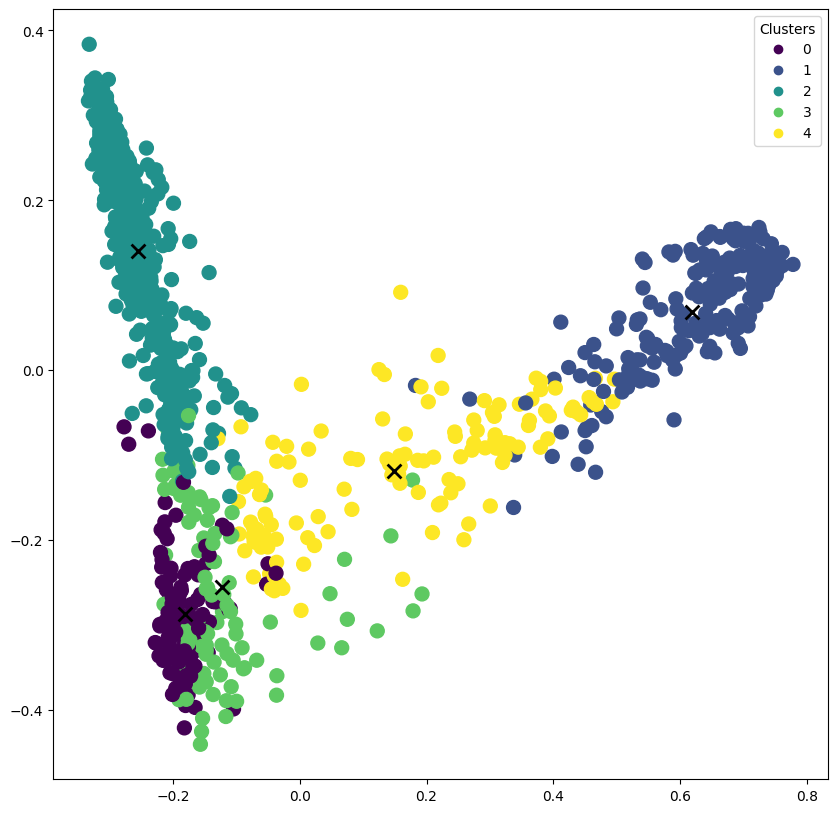

In [85]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")
plt.savefig("clusters_1940.png", dpi=200, bbox_inches="tight")